# 13 · Set 5a: offline switching policies on the Set 4 results (CPU, a few minutes)

Tests, **without generating any new model answers**, whether per-question switching can match a fixed setup at lower compute.
Everything is computed from the finished Set 4 sweep (`runs/Set_1__3-modality-size/…/results/per_question.jsonl`).

| Policy | What decides | Extra cost of deciding |
|---|---|---|
| A1 answerer cascade | cheap answerer first; bigger answerer only if its 5 answers disagree (retrieval shared) | none |
| A2 retriever cascade | small retriever first; bigger retriever only if its 3 tries disagree | none |
| A3 both cascades | A2 then A1 | none |
| A4 big answerer with 1 try | A1 / A3 with a single answer try for the bigger answerer | none |
| A5 learned router, question text | a small trained model reads the question before anything runs | negligible |
| A6 learned router, 5 facts | the Set 4 inputs (yes/no, comparison, words, digit, names) | none |
| A8 / A9 learned cascade | a trained gate on the cheap run's metadata (A9: plus the question text) | none |
| A7 Set 4 rules, smoothed | the planner's rules, with each rule's dev accuracy shrunk by an m-estimate or Laplace smoothing | none |

**Selection rule, the same for fixed setups and for every policy:** on the training questions, the cheapest candidate whose accuracy is
within 2 points of the most accurate fixed setup. **Scores are always on questions the selection did not see** (5-fold cross-validation
repeated `REPEATS` times over all 200 questions, and the Set 4 dev → test split).

Baselines in every table: the most accurate fixed setup, the cheapest fixed setup within 2 points of it, a random router with the same
mix, and a perfect router. The policies chosen on all 200 questions are saved in `frozen_policies.json` for the fresh-question test (step 5c).

Output: `runs/Set_2__question-reading-routers/<timestamp>_cpu/` with `results/summary.md`, `results/set5a_results.xlsx`, `results/charts/` (6 charts),
`results/decisions.jsonl`, `results/rules_smoothed*.jsonl`, `frozen_policies.json`, and a `sessions/<time>_offline/` folder.

**No GPU needed: Runtime → Change runtime type → CPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
SWEEP_EXPERIMENT = "Set_1__3-modality-size"     # the finished Set 4 sweep these policies are computed from
SWEEP_RUN_OVERRIDE = None             # or paste a sweep run folder; None = the latest complete one
REPEATS = 5                           # repeats of the 5-fold cross-validation
USE_EMBEDDING = True                  # also try a sentence-embedding model for the question text (downloads ~90 MB once)
NEW_RUN = True                        # each run of this notebook gets its own folder (it only takes minutes)

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import glob, json, os, shutil, subprocess, sys, time
from datetime import datetime
from zoneinfo import ZoneInfo
T_START = time.time()
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
if SWEEP_RUN_OVERRIDE:
    SWEEP_RUN = SWEEP_RUN_OVERRIDE
else:
    done = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d
            and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")
            and os.path.exists(f"{d}/results/per_question.jsonl")]
    assert done, f"No complete sweep found in runs/{SWEEP_EXPERIMENT} - finish notebook 11 first."
    SWEEP_RUN = done[-1]
DATA_DIR = json.load(open(f"{SWEEP_RUN}/config.json"))["data_dir"]
prev = sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_cpu"))
RUN_DIR = prev[-1] if (prev and not NEW_RUN) else f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_cpu"
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}_offline"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs", SESSION_DIR):
    os.makedirs(d, exist_ok=True)
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
for f in ("ssw.py", "sweep.py", "routers.py"):
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{RUN_DIR}/code/{f}")       # keep the exact code with the results
json.dump({"experiment": EXPERIMENT, "set": "5a", "sweep_run": SWEEP_RUN, "data_dir": DATA_DIR, "repeats": REPEATS,
           "use_embedding": USE_EMBEDDING, "started": SESSION}, open(f"{RUN_DIR}/config.json", "w"), indent=1)
print("Set 4 sweep used:", SWEEP_RUN)
print("Run folder:", RUN_DIR)

Set 4 sweep used: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100
Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-171948_cpu


In [4]:
# the embedding model is optional: without it the TF-IDF text features still run
if USE_EMBEDDING:
    try:
        import sentence_transformers
    except ImportError:
        print("installing sentence-transformers ...")
        !pip install -q sentence-transformers

### Run every policy (a few minutes)

In [5]:
cmd = [sys.executable, "-u", f"{CODE_DIR}/routers.py", "offline", "--sweep_run", SWEEP_RUN, "--data_dir", DATA_DIR,
       "--run_dir", RUN_DIR, "--repeats", str(REPEATS)] + ([] if USE_EMBEDDING else ["--no_embedding"])
with open(f"{RUN_DIR}/logs/offline.log", "a") as log, open(f"{SESSION_DIR}/offline.log", "a") as slog:
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        log.write(line); slog.write(line)
        print(line, end="")
    p.wait()
assert p.returncode == 0, f"failed - see {RUN_DIR}/logs/offline.log"

[09:20:29] reading /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100/results/per_question.jsonl ...
[09:20:36] 200 questions (100 dev, 100 test), 648 setups

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6183.37it/s]
[09:21:04] text embedding: all-MiniLM-L6-v2 (22.7M parameters), reduced to 16 dimensions
[09:21:05] threshold candidates: {'A1': 288, 'A4': 2016, 'A2': 432, 'A3': 1728}
[09:21:52]   cross-validation: split 5/25
[09:22:39]   cross-validation: split 10/25
[09:23:26]   cross-validation: split 15/25
[09:24:13]   cross-validation: split 20/25
[09:25:01]   cross-validation: split 25/25
[09:25:08]   dev -> test: split 1/1
[09:25:18] frozen policies chosen on all questions
[09:25:34] done in 307s -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-171948_cpu/results


### Results

# Set 5a - offline switching policies on the Set 4 results

Sweep used: `20261004-165402_A100`. 200 questions, 648 setups. No new model answers were generated.
Selection rule for every row: on the training questions, the cheapest candidate whose accuracy is within 2 points of the most accurate fixed setup. All scores below are on questions the selection did not see, except where marked in-sample.
Question-text embedding: all-MiniLM-L6-v2 (22.7M parameters), reduced to 16 dimensions.

## 1. Main result: 5-fold cross-validation x5 over all 200 questions

| Policy | Accuracy | Compute (x cheapest) | Share escalated to the bigger answerer | Share escalated to the bigger retriever | Retrieval found both | Accuracy when found | Accuracy when not found |
|---|---|---|---|---|---|---|---|
| Fixed: most accurate setup | 60.8% | 11.5x | 0.0% | 0.0% | 92.9% | 61.8% | 48.6% |
| Fixed: cheapest setup within 2 points of it | 61.7% | 5.4x | 0.0% | 0.0% | 84.8% | 63.9% | 48.1% |
| A1 answerer cascade | 60.5% | 6.3x | 40.8% | 0.0% | 85.2% | 61.0% | 55.9% |
| A2 retriever cascade | 62.1% | 6.7x | 0.0% | 28.8% | 79.5% | 64.7% | 50.8% |
| A3 retriever + answerer cascade | 58.8% | 5.7x | 49.6% | 45.4% | 76.4% | 60.9% | 50.7% |
| A4 cascade, big answerer with 1 try | 58.4% | 5.5x | 61.1% | 16.2% | 86.5% | 59.2% | 47.1% |
| A5 learned router, question text (TF-IDF) | 59.3% | 7.7x | 40.0% | 38.6% | 86.8% | 61.5% | 48.1% |
| A5 learned router, question text (embedding) | 59.3% | 7.7x | 34.5% | 32.2% | 87.0% | 61.2% | 44.7% |
| A6 learned router, 5 facts | 60.8% | 7.5x | 34.2% | 30.0% | 85.7% | 63.1% | 47.6% |
| A8 learned cascade, cheap run's metadata | 60.0% | 6.9x | 57.8% | 0.0% | 85.4% | 61.3% | 53.1% |
| A9 learned cascade, metadata + question text | 61.1% | 6.5x | 67.0% | 0.0% | 84.4% | 61.8% | 55.7% |

### Against the fixed setups

| Policy | Accuracy vs most accurate fixed [95% CI] | Compute vs most accurate fixed | Accuracy vs cheapest fixed within 2 points [95% CI] | Compute vs cheapest fixed within 2 points | Provisional verdict (final test is on fresh questions, step 5c) |
|---|---|---|---|---|---|
| Fixed: most accurate setup | +0.0 [+0.0, +0.0] | +0% | -0.9 [-3.4, +1.7] | +115% | baseline |
| Fixed: cheapest setup within 2 points of it | +0.9 [-1.7, +3.4] | -53% | +0.0 [+0.0, +0.0] | +0% | baseline |
| A1 answerer cascade | -0.3 [-3.4, +2.8] | -45% | -1.2 [-4.6, +2.3] | +17% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |
| A2 retriever cascade | +1.3 [-1.4, +3.9] | -42% | +0.4 [-2.6, +3.5] | +25% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |
| A3 retriever + answerer cascade | -2.0 [-5.6, +1.5] | -51% | -2.9 [-6.8, +1.0] | +6% | no gain over a fixed setup |
| A4 cascade, big answerer with 1 try | -2.4 [-5.5, +0.4] | -53% | -3.3 [-6.3, -0.4] | +1% | no gain over a fixed setup |
| A5 learned router, question text (TF-IDF) | -1.5 [-3.4, +0.1] | -33% | -2.4 [-4.7, -0.2] | +43% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |
| A5 learned router, question text (embedding) | -1.5 [-3.2, +0.1] | -33% | -2.4 [-4.6, -0.3] | +44% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |
| A6 learned router, 5 facts | +0.0 [-2.1, +2.1] | -35% | -0.9 [-3.2, +1.1] | +40% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |
| A8 learned cascade, cheap run's metadata | -0.8 [-3.4, +1.9] | -40% | -1.7 [-4.5, +1.2] | +28% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |
| A9 learned cascade, metadata + question text | +0.3 [-2.2, +2.8] | -43% | -0.6 [-3.5, +2.3] | +21% | meets the test against the most accurate fixed setup only (a cheaper fixed setup does as well) |

### Does the router have skill?

A policy has skill only if it beats a random router that escalates the same share of questions.

| Policy | Accuracy | Accuracy of a random router with the same mix | Accuracy of a perfect router over the same options | Gate separation (0.5 = useless) |
|---|---|---|---|---|
| A1 answerer cascade | 60.5% | 56.4% | 67.4% | 0.77 |
| A2 retriever cascade | 62.1% | 61.7% | 65.5% | 0.73 |
| A3 retriever + answerer cascade | 58.8% | 55.4% | 70.3% | 0.72 |
| A4 cascade, big answerer with 1 try | 58.4% | 56.9% | 68.0% | 0.70 |
| A5 learned router, question text (TF-IDF) | 59.3% | 59.5% | 64.6% | 0.47 |
| A5 learned router, question text (embedding) | 59.3% | 60.0% | 64.5% | 0.50 |
| A6 learned router, 5 facts | 60.8% | 59.8% | 65.0% | 0.54 |
| A8 learned cascade, cheap run's metadata | 60.0% | 57.0% | 66.4% | 0.73 |
| A9 learned cascade, metadata + question text | 61.1% | 58.8% | 67.5% | 0.70 |

### Which exact policy was selected most often

| Policy | Most often selected | Selected in share of splits |
|---|---|---|
| Fixed: most accurate setup | Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all) | 44.0% |
| Fixed: cheapest setup within 2 points of it | Qwen 7B retrieves x1, Qwen 32B answers x1 (CoT on, per-attempt shortlist 3, final shortlist all) | 56.0% |
| A1 answerer cascade | Qwen 7B retrieves; Llama 8B answers x5; Qwen 32B x5 answers unless at least 4 of 5 agree (CoT on, per-attempt shortlist paper default, final shortlist all) | 52.0% |
| A2 retriever cascade | Qwen 7B retrieves; Qwen 32B retrieves again if agreement of the 3 tries is below 0.4; Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all) | 36.0% |
| A3 retriever + answerer cascade | Qwen 3B retrieves; Qwen 7B retrieves again if agreement of the 3 tries is below 0.7; Llama 8B answers x5; Qwen 32B x5 answers unless at least 4 of 5 agree (CoT on, per-attempt shortlist paper default, final shortlist all) | 32.0% |
| A4 cascade, big answerer with 1 try | Qwen 7B retrieves; Llama 3B answers x5; Qwen 32B x1 answers unless all 5 agree (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 20.0% |
| A5 learned router, question text (TF-IDF) | a trained router reads the question and sends it to [Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all)] or to [Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all)]; the lowest-scoring 20% of questions go to the big option | 16.0% |
| A5 learned router, question text (embedding) | a trained router reads the question and sends it to [Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all)] or to [Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all)]; the lowest-scoring 20% of questions go to the big option | 20.0% |
| A6 learned router, 5 facts | a trained router reads the question and sends it to [Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all)] or to [Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all)]; the lowest-scoring 20% of questions go to the big option | 20.0% |
| A8 learned cascade, cheap run's metadata | Qwen 7B retrieves; Llama 3B answers x5; a trained gate decides whether Qwen 32B x5 also answers (CoT on, per-attempt shortlist paper default, final shortlist all); the lowest-scoring 80% of questions go to the big option | 24.0% |
| A9 learned cascade, metadata + question text | Qwen 7B retrieves; Llama 3B answers x5; a trained gate decides whether Qwen 32B x5 also answers (CoT on, per-attempt shortlist paper default, final shortlist all); the lowest-scoring 80% of questions go to the big option | 20.0% |

## 2. Same policies, chosen on dev (100) and scored on test (100), as in Set 4

| Policy | Accuracy | Compute (x cheapest) | Share escalated to the bigger answerer | Share escalated to the bigger retriever | Retrieval found both | Accuracy when found | Accuracy when not found |
|---|---|---|---|---|---|---|---|
| Fixed: most accurate setup | 64.0% | 4.5x | 0.0% | 0.0% | 84.0% | 66.7% | 50.0% |
| Fixed: cheapest setup within 2 points of it | 66.0% | 4.2x | 0.0% | 0.0% | 83.0% | 69.9% | 47.1% |
| A1 answerer cascade | 62.0% | 6.4x | 60.0% | 0.0% | 84.0% | 64.3% | 50.0% |
| A2 retriever cascade | 64.0% | 6.4x | 0.0% | 46.0% | 84.0% | 67.9% | 43.8% |
| A3 retriever + answerer cascade | 59.0% | 4.7x | 8.0% | 79.0% | 90.0% | 61.1% | 40.0% |
| A4 cascade, big answerer with 1 try | 64.0% | 4.5x | 78.0% | 0.0% | 84.0% | 66.7% | 50.0% |
| A5 learned router, question text (TF-IDF) | 62.0% | 3.9x | 82.0% | 82.0% | 73.0% | 69.9% | 40.7% |
| A5 learned router, question text (embedding) | 52.0% | 3.6x | 74.0% | 74.0% | 69.0% | 59.4% | 35.5% |
| A6 learned router, 5 facts | 58.0% | 3.7x | 75.0% | 75.0% | 67.0% | 64.2% | 45.5% |
| A8 learned cascade, cheap run's metadata | 62.0% | 10.7x | 54.0% | 0.0% | 72.0% | 61.1% | 64.3% |
| A9 learned cascade, metadata + question text | 66.0% | 5.3x | 44.0% | 0.0% | 78.0% | 66.7% | 63.6% |


| Policy | Accuracy vs most accurate fixed [95% CI] | Compute vs most accurate fixed | Accuracy vs cheapest fixed within 2 points [95% CI] | Compute vs cheapest fixed within 2 points | Provisional verdict (final test is on fresh questions, step 5c) |
|---|---|---|---|---|---|
| Fixed: most accurate setup | +0.0 [+0.0, +0.0] | +0% | -2.0 [-6.0, +2.0] | +6% | baseline |
| Fixed: cheapest setup within 2 points of it | +2.0 [-2.0, +6.0] | -6% | +0.0 [+0.0, +0.0] | +0% | baseline |
| A1 answerer cascade | -2.0 [-8.0, +4.0] | +42% | -4.0 [-11.0, +3.0] | +51% | no gain over a fixed setup |
| A2 retriever cascade | +0.0 [-6.0, +6.0] | +43% | -2.0 [-8.0, +4.0] | +52% | no gain over a fixed setup |
| A3 retriever + answerer cascade | -5.0 [-14.0, +4.0] | +4% | -7.0 [-16.0, +2.0] | +10% | no gain over a fixed setup |
| A4 cascade, big answerer with 1 try | +0.0 [-3.0, +3.0] | +1% | -2.0 [-7.0, +3.0] | +7% | no gain over a fixed setup |
| A5 learned router, question text (TF-IDF) | -2.0 [-5.0, +0.0] | -13% | -4.0 [-9.0, +0.0] | -8% | no gain over a fixed setup |
| A5 learned router, question text (embedding) | -12.0 [-19.0, -6.0] | -20% | -14.0 [-22.0, -7.0] | -15% | no gain over a fixed setup |
| A6 learned router, 5 facts | -6.0 [-11.0, -2.0] | -18% | -8.0 [-14.0, -2.0] | -14% | no gain over a fixed setup |
| A8 learned cascade, cheap run's metadata | -2.0 [-9.0, +5.0] | +138% | -4.0 [-11.0, +3.0] | +153% | no gain over a fixed setup |
| A9 learned cascade, metadata + question text | +2.0 [-6.0, +10.0] | +18% | +0.0 [-8.0, +8.0] | +25% | no gain over a fixed setup |

## 3. Frozen policies for step 5c (chosen on all 200 questions; these numbers are in-sample)

| Policy | Exact policy | Accuracy (all 200, in-sample) | Compute (x cheapest) |
|---|---|---|---|
| Fixed: most accurate setup | Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all) | 65.0% | 11.2x |
| Fixed: cheapest setup within 2 points of it | Qwen 7B retrieves x1, Qwen 32B answers x1 (CoT on, per-attempt shortlist 3, final shortlist all) | 63.5% | 4.2x |
| A1 answerer cascade | Qwen 7B retrieves; Llama 8B answers x5; Qwen 32B x5 answers unless at least 4 of 5 agree (CoT on, per-attempt shortlist paper default, final shortlist all) | 63.5% | 5.0x |
| A2 retriever cascade | Qwen 7B retrieves; Qwen 32B retrieves again if agreement of the 3 tries is below 0.4; Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all) | 63.5% | 6.1x |
| A3 retriever + answerer cascade | Qwen 3B retrieves; Qwen 7B retrieves again if agreement of the 3 tries is below 0.7; Llama 8B answers x5; Qwen 32B x5 answers unless at least 4 of 5 agree (CoT on, per-attempt shortlist paper default, final shortlist all) | 63.5% | 5.4x |
| A4 cascade, big answerer with 1 try | Qwen 7B retrieves; Qwen 32B retrieves again if agreement of the 3 tries is below 0.4; Llama 3B answers x5; Qwen 32B x1 answers unless all 5 agree (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 63.0% | 4.9x |
| A5 learned router, question text (TF-IDF) | a trained router reads the question and sends it to [Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all)] or to [Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all)]; the lowest-scoring 20% of questions go to the big option | 63.0% | 6.9x |
| A5 learned router, question text (embedding) | a trained router reads the question and sends it to [Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all)] or to [Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all)]; the lowest-scoring 20% of questions go to the big option | 63.5% | 6.9x |
| A6 learned router, 5 facts | a trained router reads the question and sends it to [Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all)] or to [Qwen 32B retrieves x1, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all)]; the lowest-scoring 20% of questions go to the big option | 64.0% | 6.9x |
| A8 learned cascade, cheap run's metadata | Qwen 7B retrieves; Llama 3B answers x5; a trained gate decides whether Qwen 32B x5 also answers (CoT on, per-attempt shortlist paper default, final shortlist all); the lowest-scoring 80% of questions go to the big option | 64.0% | 5.6x |
| A9 learned cascade, metadata + question text | Qwen 7B retrieves; Llama 8B answers x5; a trained gate decides whether Qwen 32B x5 also answers (CoT on, per-attempt shortlist paper default, final shortlist all); the lowest-scoring 35% of questions go to the big option | 63.5% | 5.0x |

## 4. How much is there to gain? (all 200 questions)

| Quantity | Value | Note |
|---|---|---|
| Most accurate of the 5 routes on the cost-accuracy frontier | 65.0% | Qwen 32B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist all) |
| Perfect router over those 5 routes | 73.5% | hindsight: right if any route is right |
| Perfect router over 5 near-identical copies of the best route (luck only) | 69.5% | same models, only the shortlist settings differ; mean of 300 random draws of 5 from 9 |
| Questions where the best route is right | 65.0% |  |
| Questions where the best route is wrong and a cheaper route is right | 8.5% |  |
| Questions where no route is right | 26.5% |  |
| Questions where every route is right | 14.5% |  |

## 5. Does more training data help the gate?

Reference pair: cheap = Qwen 7B retrieves x3, Llama 8B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all); big = Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist all); share of questions where the cheap answer is no worse: 86%.

Values at or below 0.5 mean no usable signal; with few held-out questions an input without signal often scores below 0.5.

| Inputs the gate sees | Training questions | Separation on held-out questions (0.5 = useless) | standard error |
|---|---|---|---|
| 5 facts about the question | 40 | 0.44 | 0.01 |
| question text (TF-IDF) | 40 | 0.52 | 0.01 |
| cheap run's metadata | 40 | 0.74 | 0.01 |
| metadata + question text | 40 | 0.66 | 0.01 |
| question text (embedding) | 40 | 0.50 | 0.01 |
| 5 facts about the question | 80 | 0.43 | 0.01 |
| question text (TF-IDF) | 80 | 0.54 | 0.01 |
| cheap run's metadata | 80 | 0.76 | 0.01 |
| metadata + question text | 80 | 0.71 | 0.01 |
| question text (embedding) | 80 | 0.51 | 0.01 |
| 5 facts about the question | 120 | 0.39 | 0.01 |
| question text (TF-IDF) | 120 | 0.57 | 0.01 |
| cheap run's metadata | 120 | 0.79 | 0.01 |
| metadata + question text | 120 | 0.75 | 0.01 |
| question text (embedding) | 120 | 0.49 | 0.01 |
| 5 facts about the question | 160 | 0.31 | 0.02 |
| question text (TF-IDF) | 160 | 0.53 | 0.03 |
| cheap run's metadata | 160 | 0.80 | 0.01 |
| metadata + question text | 160 | 0.74 | 0.02 |
| question text (embedding) | 160 | 0.46 | 0.02 |

## 6. A7: the Set 4 rules with smoothed statistics (chosen on dev, scored on test)

A rule is dropped when its smoothed dev accuracy, net of cost, is below that of the single best route on the same questions. m-estimate: (correct + m x the route's overall dev accuracy) / (fired + m). Mean over the 19 scopes of Set 4.

| Rules applied | Variant | Scopes | Mean rules kept | Mean test accuracy | Mean test compute (x cheapest) | Mean test accuracy of the single fallback route | Mean test compute of the fallback route |
|---|---|---|---|---|---|---|---|
| after small pipeline | as written in Set 4 | 19 | 8.00 | 50.9% | 7.7x | 46.6% | 4.7x |
| after small pipeline | pruned on raw counts (m = 0) | 19 | 3.79 | 48.2% | 5.1x | 46.6% | 4.7x |
| after small pipeline | pruned with m-estimate, m = 2 | 19 | 3.79 | 48.2% | 5.1x | 46.6% | 4.7x |
| after small pipeline | pruned with m-estimate, m = 5 | 19 | 3.63 | 47.6% | 4.8x | 46.6% | 4.7x |
| after small pipeline | pruned with m-estimate, m = 10 | 19 | 3.47 | 46.9% | 4.6x | 46.6% | 4.7x |
| after small pipeline | pruned with Laplace smoothing | 19 | 3.95 | 45.7% | 4.6x | 46.6% | 4.7x |
| question only | as written in Set 4 | 19 | 7.95 | 52.1% | 6.1x | 48.9% | 4.1x |
| question only | pruned on raw counts (m = 0) | 19 | 4.16 | 47.9% | 4.1x | 48.9% | 4.1x |
| question only | pruned with m-estimate, m = 2 | 19 | 3.79 | 47.5% | 3.9x | 48.9% | 4.1x |
| question only | pruned with m-estimate, m = 5 | 19 | 3.79 | 47.3% | 3.9x | 48.9% | 4.1x |
| question only | pruned with m-estimate, m = 10 | 19 | 3.58 | 47.4% | 3.9x | 48.9% | 4.1x |
| question only | pruned with Laplace smoothing | 19 | 4.47 | 45.7% | 3.7x | 48.9% | 4.1x |

### The planner's rules for the whole sweep, with raw and smoothed accuracy (m = 5)


**after small pipeline**

| rule | route means | planner's confidence | dev questions it fired on | raw dev accuracy | smoothed dev accuracy | smoothed dev accuracy of the fallback route on the same questions | kept |
|---|---|---|---|---|---|---|---|
| IF yesno = yes THEN G1 | Qwen 3B retrieves x3, Llama 3B answers x5 (CoT off, per-attempt shortlist paper default, final shortlist paper default (vote)) | 75.0% | 4 | 75.0% | 52.8% | 75.0% | False |
| IF words > 16 AND ans_conf > 0.9 THEN G1 | Qwen 3B retrieves x3, Llama 3B answers x5 (CoT off, per-attempt shortlist paper default, final shortlist paper default (vote)) | 70.0% | 23 | 56.5% | 52.7% | 56.2% | True |
| IF compare = yes AND ret_agree <= 0.725 THEN G5 | Qwen 32B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 65.0% | 16 | 62.5% | 62.6% | 60.7% | False |
| IF digit = yes AND ret_agree <= 0.725 THEN G5 | Qwen 32B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 65.0% | 3 | 66.7% | 64.4% | 59.4% | False |
| IF names > 3 AND ans_agree > 0.6 THEN G5 | Qwen 32B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 60.0% | 7 | 42.9% | 51.3% | 47.9% | False |
| IF ret_agree > 0.725 AND ans_agree > 0.6 THEN G4 | Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist paper default (vote)) | 60.0% | 10 | 90.0% | 79.7% | 58.3% | True |
| IF ans_conf > 0.9 THEN G2 | Qwen 3B retrieves x3, Llama 3B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 55.0% | 7 | 42.9% | 43.8% | 47.9% | True |
| OTHERWISE G3 | Qwen 7B retrieves x3, Llama 8B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 55.0% | 30 | 46.7% | 47.9% | 47.9% | True |

**question only**

| rule | route means | planner's confidence | dev questions it fired on | raw dev accuracy | smoothed dev accuracy | smoothed dev accuracy of the fallback route on the same questions | kept |
|---|---|---|---|---|---|---|---|
| IF yesno = yes THEN G1 | Qwen 3B retrieves x3, Llama 3B answers x5 (CoT off, per-attempt shortlist paper default, final shortlist paper default (vote)) | 75.0% | 4 | 75.0% | 52.8% | 75.0% | False |
| IF compare = yes AND words > 16 THEN G5 | Qwen 32B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 68.0% | 14 | 78.6% | 74.5% | 72.4% | False |
| IF compare = yes AND words <= 16 THEN G4 | Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist paper default (vote)) | 65.0% | 19 | 52.6% | 54.0% | 49.0% | False |
| IF words > 16 AND digit = yes THEN G5 | Qwen 32B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 71.0% | 8 | 62.5% | 62.7% | 59.6% | False |
| IF words > 16 AND digit = no THEN G4 | Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist paper default (vote)) | 67.0% | 22 | 68.2% | 66.5% | 54.6% | True |
| IF digit = yes THEN G3 | Qwen 7B retrieves x3, Llama 8B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 65.0% | 4 | 50.0% | 52.8% | 52.8% | True |
| IF names > 3 THEN G4 | Qwen 7B retrieves x3, Qwen 32B answers x5 (CoT on, per-attempt shortlist paper default, final shortlist paper default (vote)) | 59.0% | 9 | 33.3% | 42.5% | 33.9% | True |
| OTHERWISE G3 | Qwen 7B retrieves x3, Llama 8B answers x5 (CoT on, per-attempt shortlist 3, final shortlist paper default (vote)) | 55.0% | 20 | 50.0% | 51.0% | 51.0% | True |

Charts: `results/charts/`. Excel: `results/set5a_results.xlsx`. Every question's path under each frozen policy: `results/decisions.jsonl`. Frozen policies for step 5c: `frozen_policies.json`.


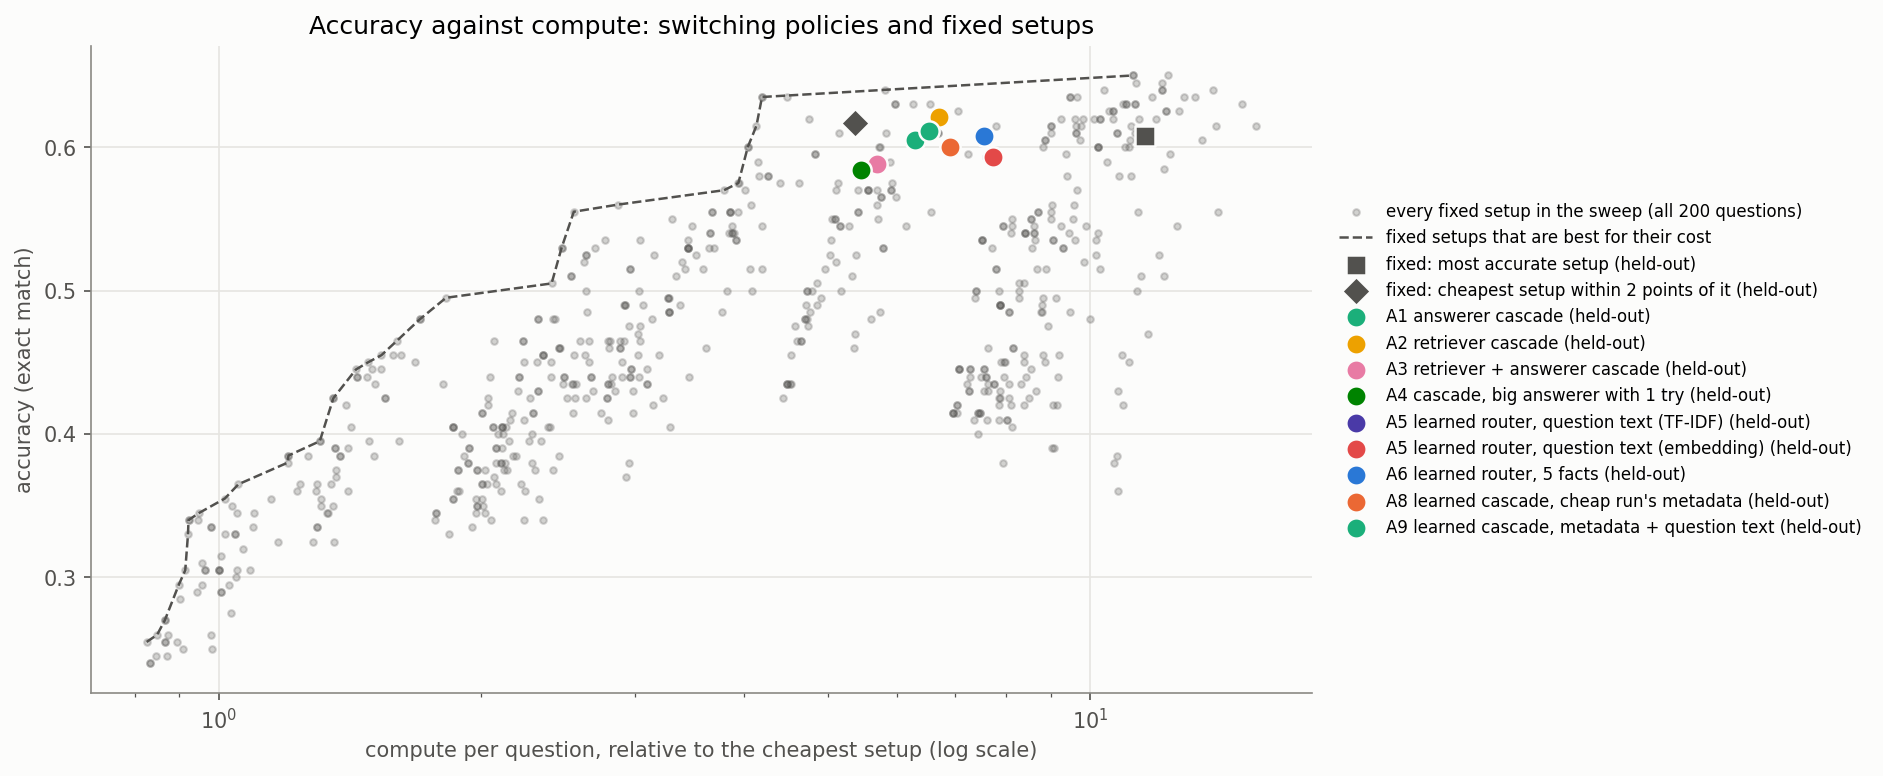

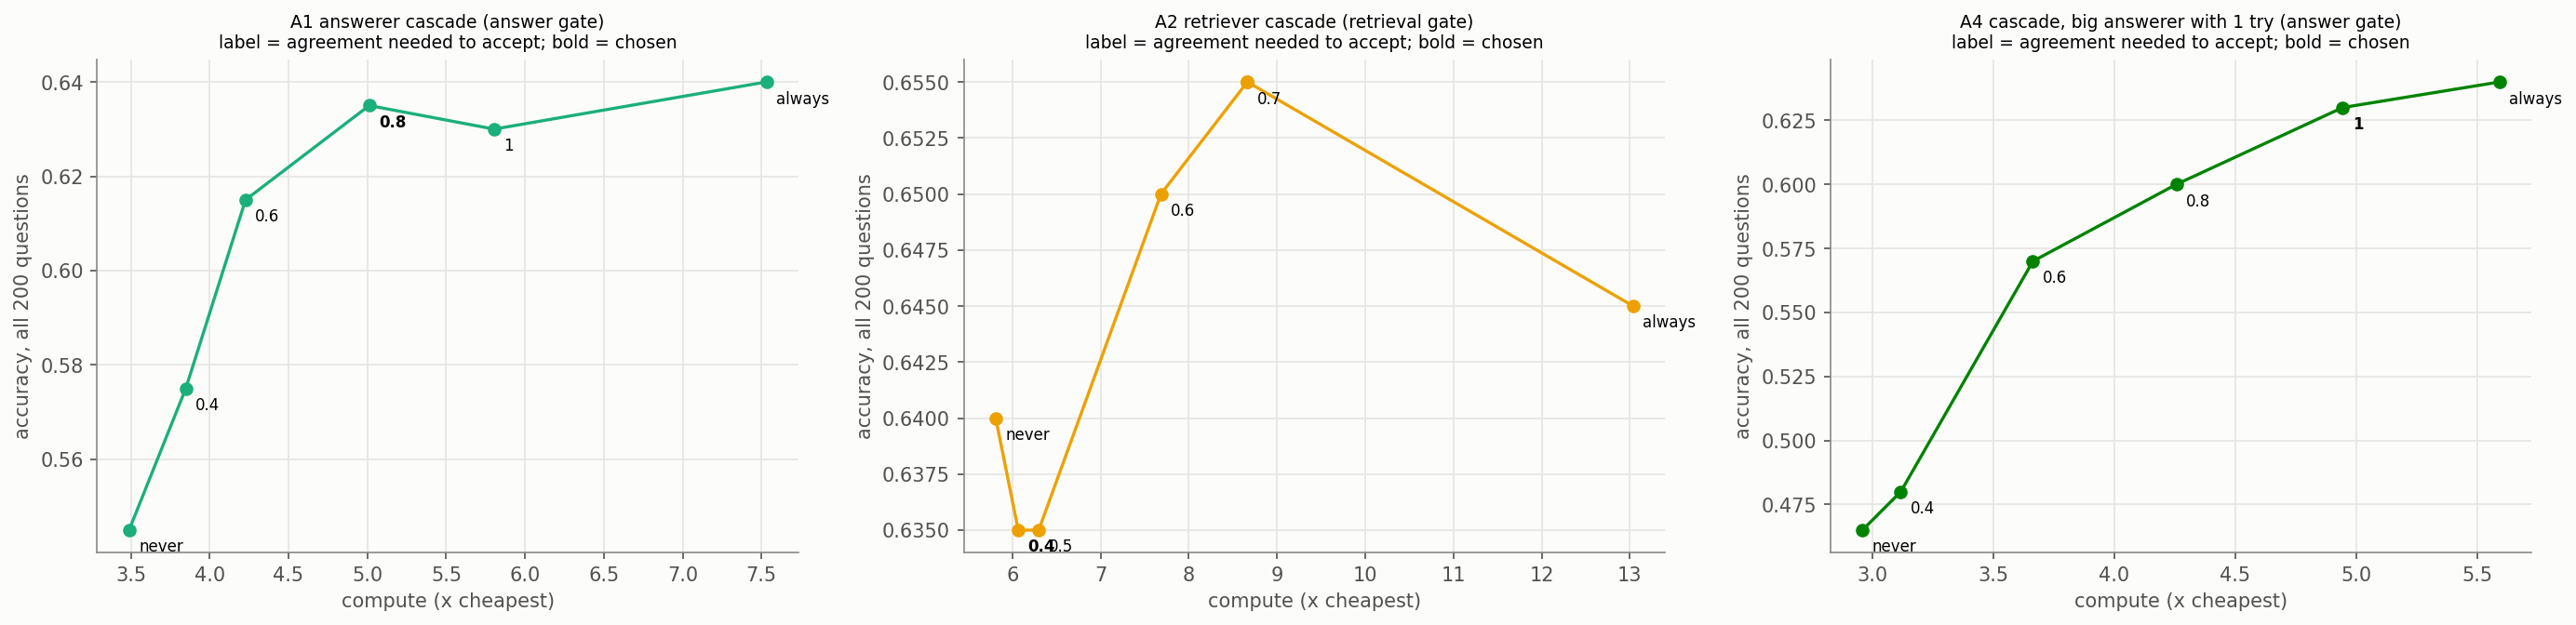

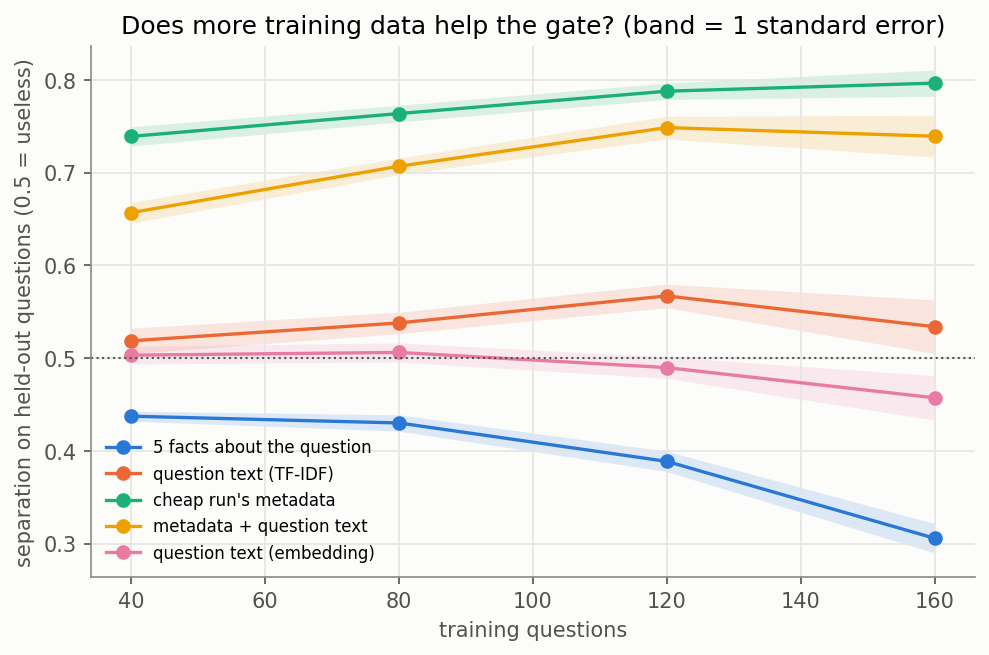

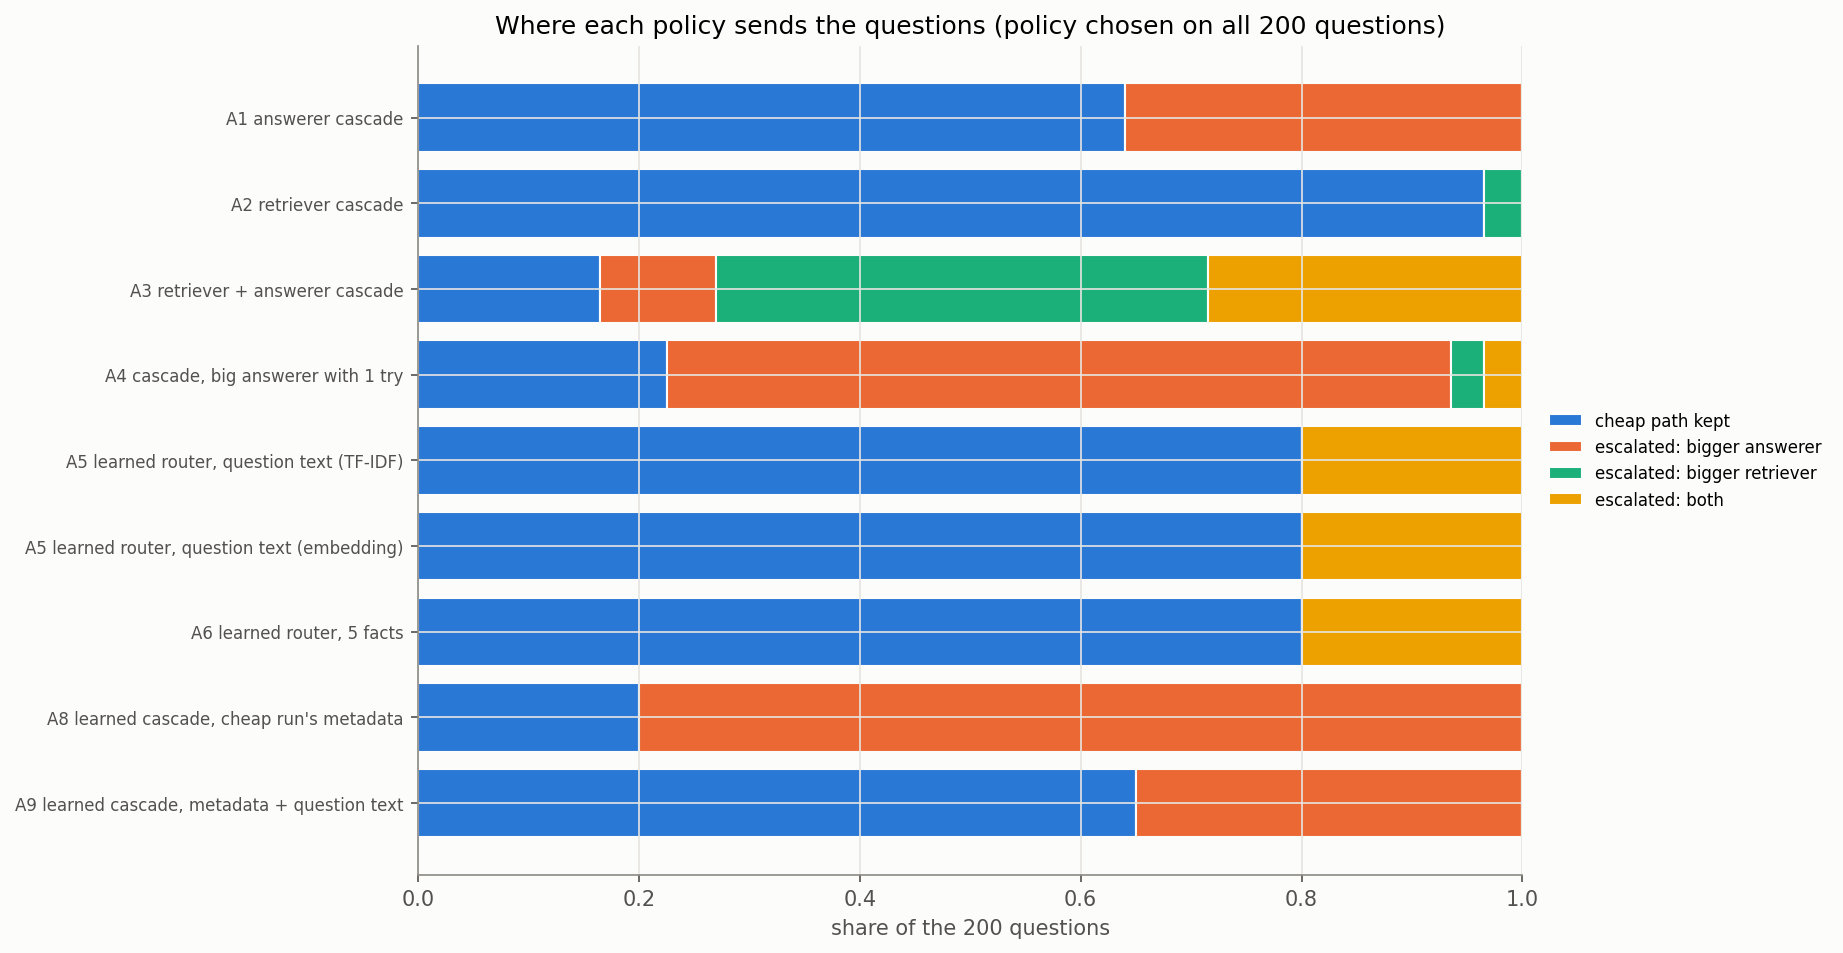

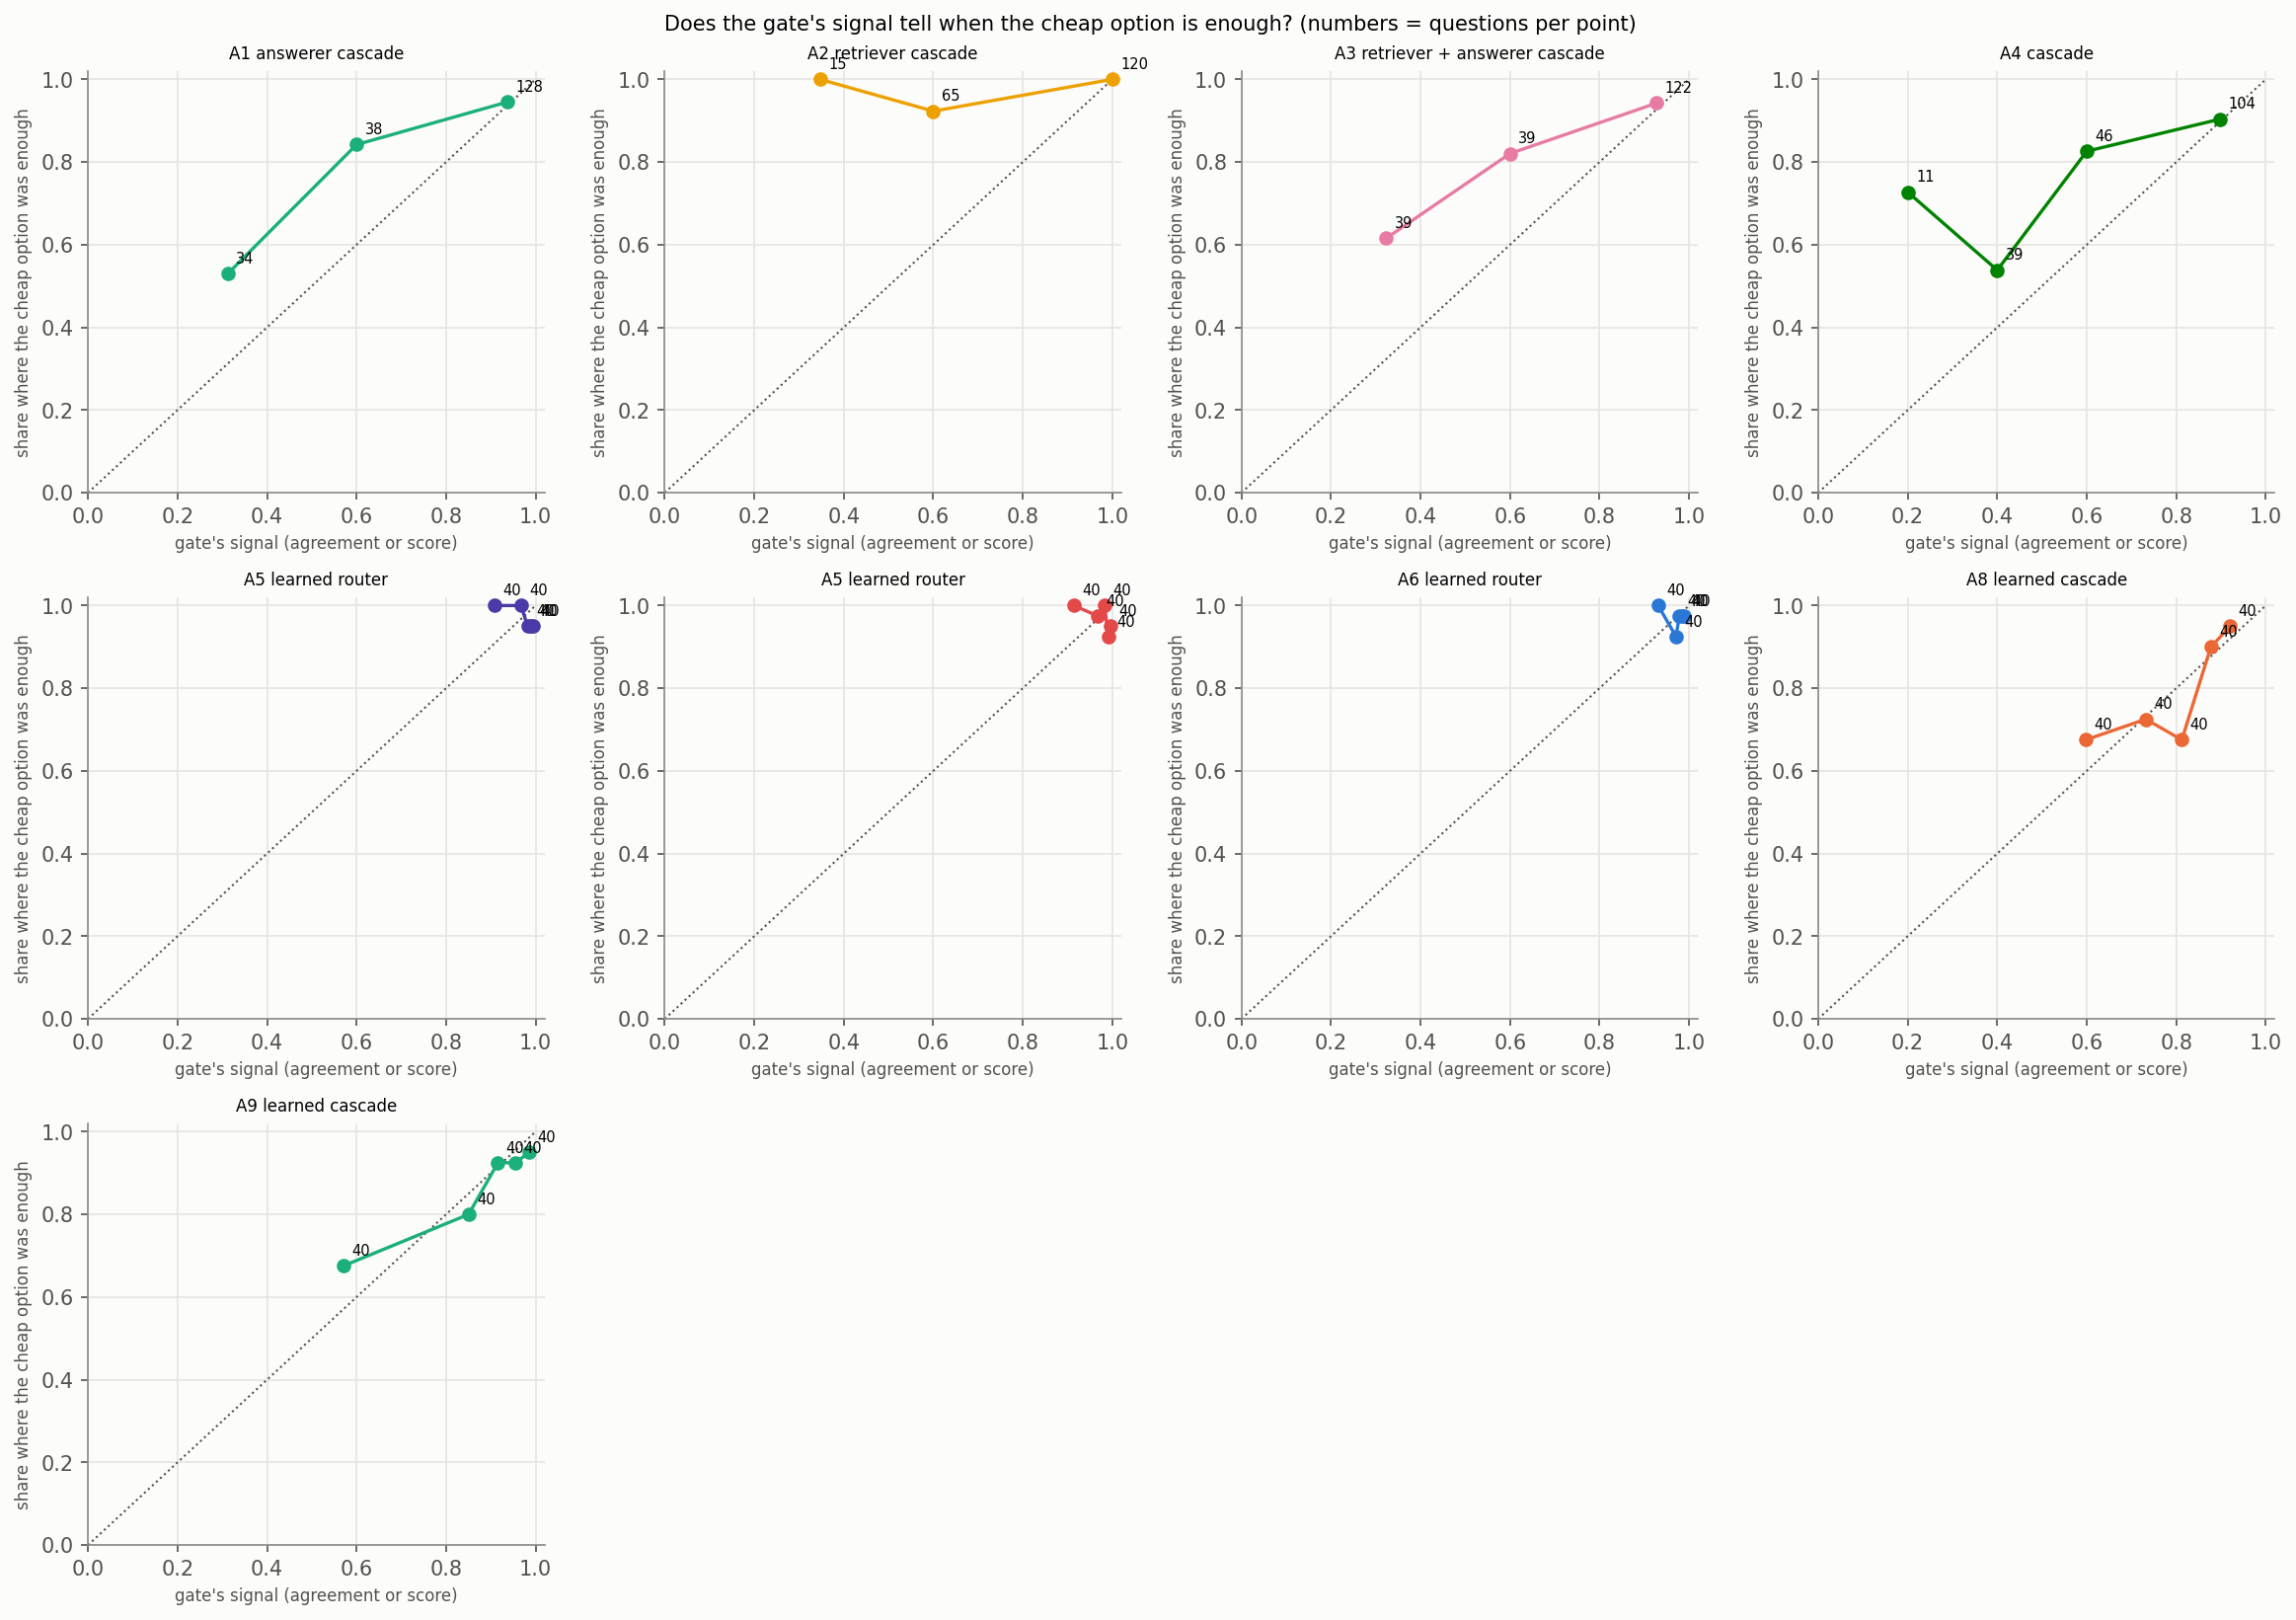

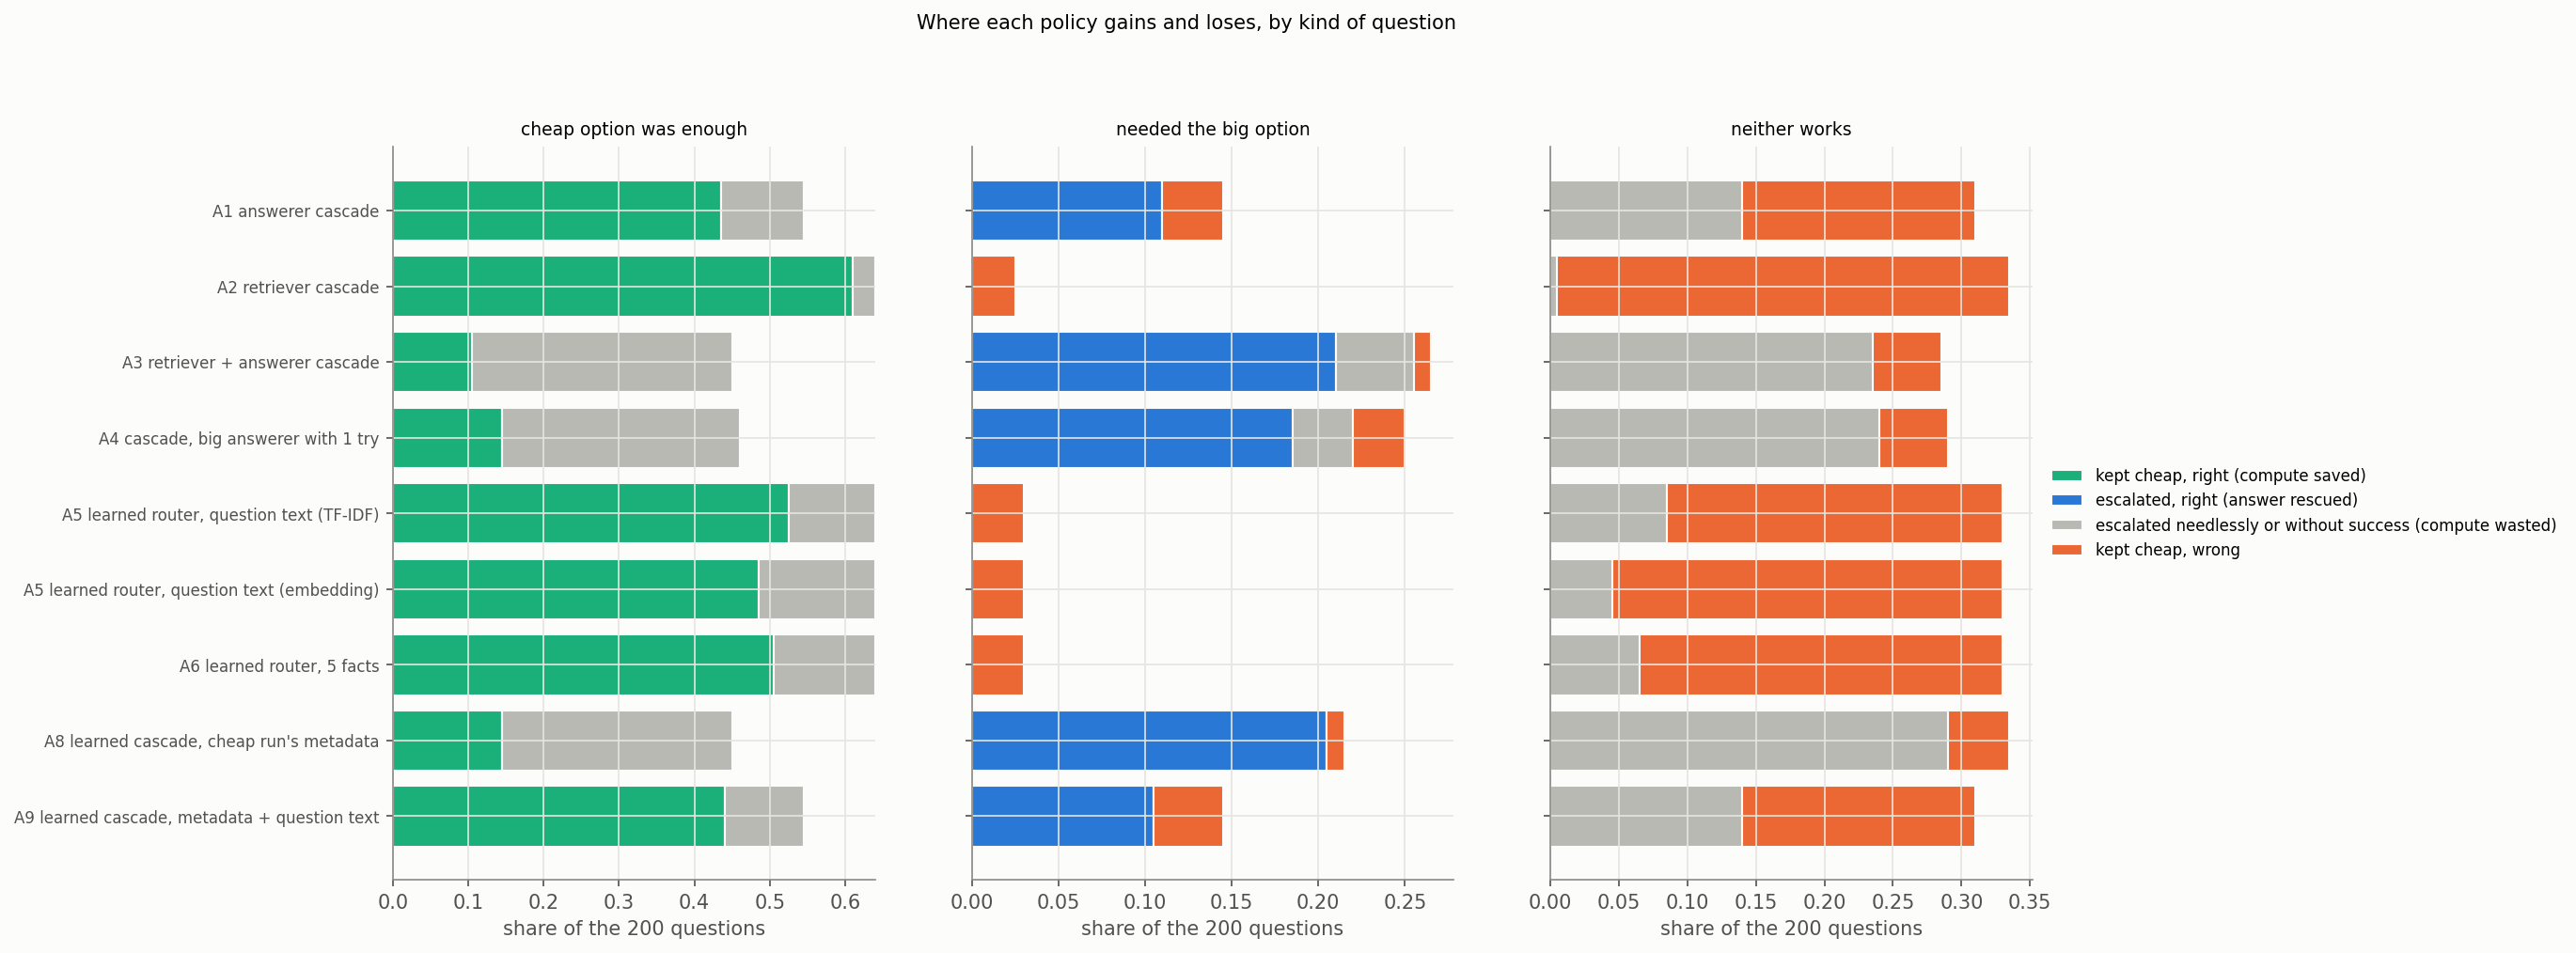

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-171948_cpu/results/set5a_results.xlsx
Frozen policies for step 5c: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-171948_cpu/frozen_policies.json
Wall-clock this session (s): {'total_session': 348}
Saved to Drive.


In [6]:
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
    display(Image(f))
os.makedirs(f"{SESSION_DIR}/results_snapshot", exist_ok=True)
for f in ("summary.md", "set5a_results.xlsx", "policies.jsonl"):
    shutil.copy(f"{RUN_DIR}/results/{f}", f"{SESSION_DIR}/results_snapshot/{f}")
shutil.copytree(f"{RUN_DIR}/results/charts", f"{SESSION_DIR}/results_snapshot/charts", dirs_exist_ok=True)
shutil.copy(f"{RUN_DIR}/frozen_policies.json", f"{SESSION_DIR}/frozen_policies.json")
TIMES = {"total_session": round(time.time() - T_START)}
json.dump({"session": SESSION, "label": "offline", "sweep_run": SWEEP_RUN, "run_dir": RUN_DIR, "seconds": TIMES,
           "status": json.load(open(f"{RUN_DIR}/offline_status.json"))}, open(f"{SESSION_DIR}/session.json", "w"), indent=1)
print("Excel workbook:", f"{RUN_DIR}/results/set5a_results.xlsx")
print("Frozen policies for step 5c:", f"{RUN_DIR}/frozen_policies.json")
print("Wall-clock this session (s):", TIMES)
try:
    drive.flush_and_unmount()          # make sure everything reaches Drive
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)